In [21]:
import pandas as pd
import numpy as np

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix



In [22]:
from sklearn.datasets import load_breast_cancer

# Load the breast cancer dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")


print("Feature Names:")
print(X.columns.tolist())
print("Dataset shape:", X.shape)

Feature Names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
Dataset shape: (569, 30)


In [23]:
print("Target:")
print(y.unique().tolist())
print("Target shape:", y.shape)
print(dict(enumerate(data.target_names)))

Target:
[0, 1]
Target shape: (569,)
{0: np.str_('malignant'), 1: np.str_('benign')}


In [24]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [25]:
X.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [26]:
y.info()

<class 'pandas.core.series.Series'>
RangeIndex: 569 entries, 0 to 568
Series name: target
Non-Null Count  Dtype
--------------  -----
569 non-null    int64
dtypes: int64(1)
memory usage: 4.6 KB


In [27]:
y.describe()

count    569.000000
mean       0.627417
std        0.483918
min        0.000000
25%        0.000000
50%        1.000000
75%        1.000000
max        1.000000
Name: target, dtype: float64

In [28]:
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [29]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64

In [30]:
print("Duplicate Rows:", X.duplicated().sum())

Duplicate Rows: 0


In [31]:
print(X.isnull().sum().sum())
print(y.isnull().sum().sum())

0
0


If all values are 0, there are no missing values, so no imputation is required.

In [32]:
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outlier_count = ((X < lower) | (X > upper)).sum()
print(outlier_count)

mean radius                14
mean texture                7
mean perimeter             13
mean area                  25
mean smoothness             6
mean compactness           16
mean concavity             18
mean concave points        10
mean symmetry              15
mean fractal dimension     15
radius error               38
texture error              20
perimeter error            38
area error                 65
smoothness error           30
compactness error          28
concavity error            22
concave points error       19
symmetry error             27
fractal dimension error    28
worst radius               17
worst texture               5
worst perimeter            15
worst area                 35
worst smoothness            7
worst compactness          16
worst concavity            12
worst concave points        0
worst symmetry             23
worst fractal dimension    24
dtype: int64


In [33]:
print("Total outliers:", outlier_count.sum())

Total outliers: 608


In [34]:
X=X.clip(lower=lower,upper=upper,axis=1)

In [35]:
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outlier_count = ((X < lower) | (X > upper)).sum()
print(outlier_count)

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64


In [36]:
Q1 = y.quantile(0.25)
Q3 = y.quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outlier_count = ((y < lower) | (y > upper)).sum()
print(outlier_count)

0


In [37]:
print(y.value_counts())

target
1    357
0    212
Name: count, dtype: int64


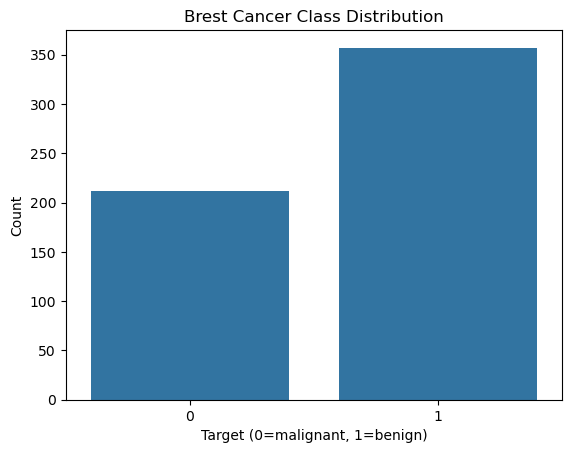

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(x=y)
plt.title("Brest Cancer Class Distribution")
plt.xlabel("Target (0=malignant, 1=benign)")
plt.ylabel("Count")
plt.show()

In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train.shape:", X_train.shape)
print("X_test.shape:", X_test.shape)
print("y_train.shape:", y_train.shape)
print("y_test.shape:", y_test.shape)

X_train.shape: (455, 30)
X_test.shape: (114, 30)
y_train.shape: (455,)
y_test.shape: (114,)


In [40]:
import sklearn.preprocessing
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Logistic Regression

Used for binary classification.

Predicts the probability of a data point belonging to a class.

Uses the logistic (sigmoid) function to make predictions.

Why suitable:

Breast Cancer dataset is a classification problem.

It contains numerical features.

Works well as a simple baseline model.

In [41]:
#A. Logistic Regression
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train_scaled, y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [42]:
y_pred_logistic = logistic_model.predict(X_test_scaled)

In [43]:
y_pred_logistic  = logistic_model.predict(X_test_scaled)
y_prob = logistic_model.predict_proba(X_test_scaled)[:, 1]
accuracy_logistic=accuracy_score(y_test, y_pred_logistic )
print("Accuracy:",accuracy_logistic )
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_logistic ))
print("Classification Report:\n", classification_report(y_test, y_pred_logistic ))

Accuracy: 0.9824561403508771
Confusion Matrix:
 [[41  1]
 [ 1 71]]
Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [46]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': logistic_model.coef_[0]
})

coefficients = coefficients.sort_values(
    by='Coefficient',
    ascending=False
)

print("coefficients:\n",coefficients)

coefficients:
                     Feature  Coefficient
15        compactness error     1.006546
5          mean compactness     0.606070
19  fractal dimension error     0.516428
18           symmetry error     0.477474
11            texture error     0.276813
14         smoothness error     0.134287
25        worst compactness     0.059938
9    mean fractal dimension    -0.041617
29  worst fractal dimension    -0.141093
16          concavity error    -0.161871
8             mean symmetry    -0.198016
4           mean smoothness    -0.270825
2            mean perimeter    -0.425165
12          perimeter error    -0.425744
0               mean radius    -0.437221
3                 mean area    -0.527223
22          worst perimeter    -0.636270
17     concave points error    -0.668380
6            mean concavity    -0.673383
7       mean concave points    -0.693622
1              mean texture    -0.716080
10             radius error    -0.751739
26          worst concavity    -0.751742
2

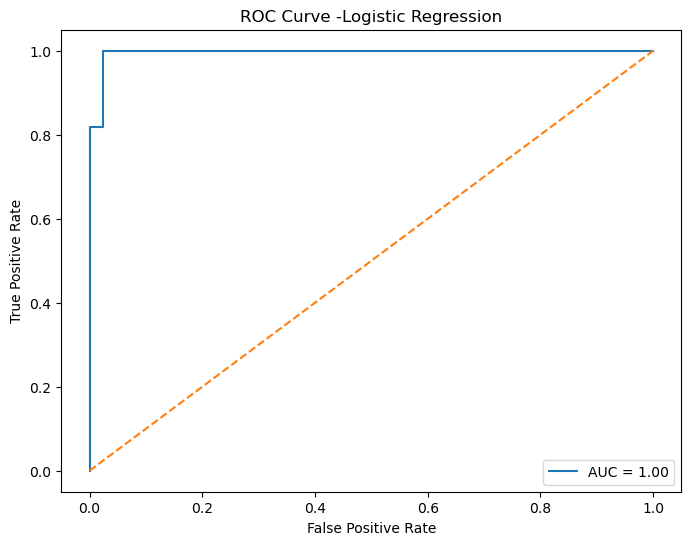

ROC-AUC: 0.9957010582010581


In [84]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Probability of class 1
y_prob = logistic_model.predict_proba(X_test_scaled)[:, 1]

# ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# AUC
roc_auc_logistic = roc_auc_score(y_test, y_prob)

# Plot ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_logistic:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve -Logistic Regression")
plt.legend()
plt.show()

print("ROC-AUC:", roc_auc_logistic)

In [47]:
df1=pd.DataFrame({"Actual":y_test,"Predicted":y_pred_logistic})
df1

,Actual,Predicted
256,0,0
428,1,1
501,0,0
363,1,1
564,0,0
...,...,...
95,0,0
128,1,1
257,0,0
228,1,1


Decision Tree


It makes decisions using different conditions.
    
It splits the data into smaller groups.
    
It gives a final class as the output.
    
Suitable:

It can handle numerical features easily.
    
It is simple to understand and interpret.
    


In [48]:
dt_model = DecisionTreeClassifier(max_depth=5,random_state=42)

dt_model.fit(X_train, y_train)



,criterion,'gini'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [49]:
y_pred_dt = dt_model.predict(X_test)


In [50]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)
print("Decision Tree Accuracy:", accuracy_dt)

Decision Tree Accuracy: 0.9210526315789473


In [51]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

print("\nConfusion Matrix:")
print(cm_dt)


Confusion Matrix:
[[39  3]
 [ 6 66]]


In [52]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))


Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.93      0.90        42
           1       0.96      0.92      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114



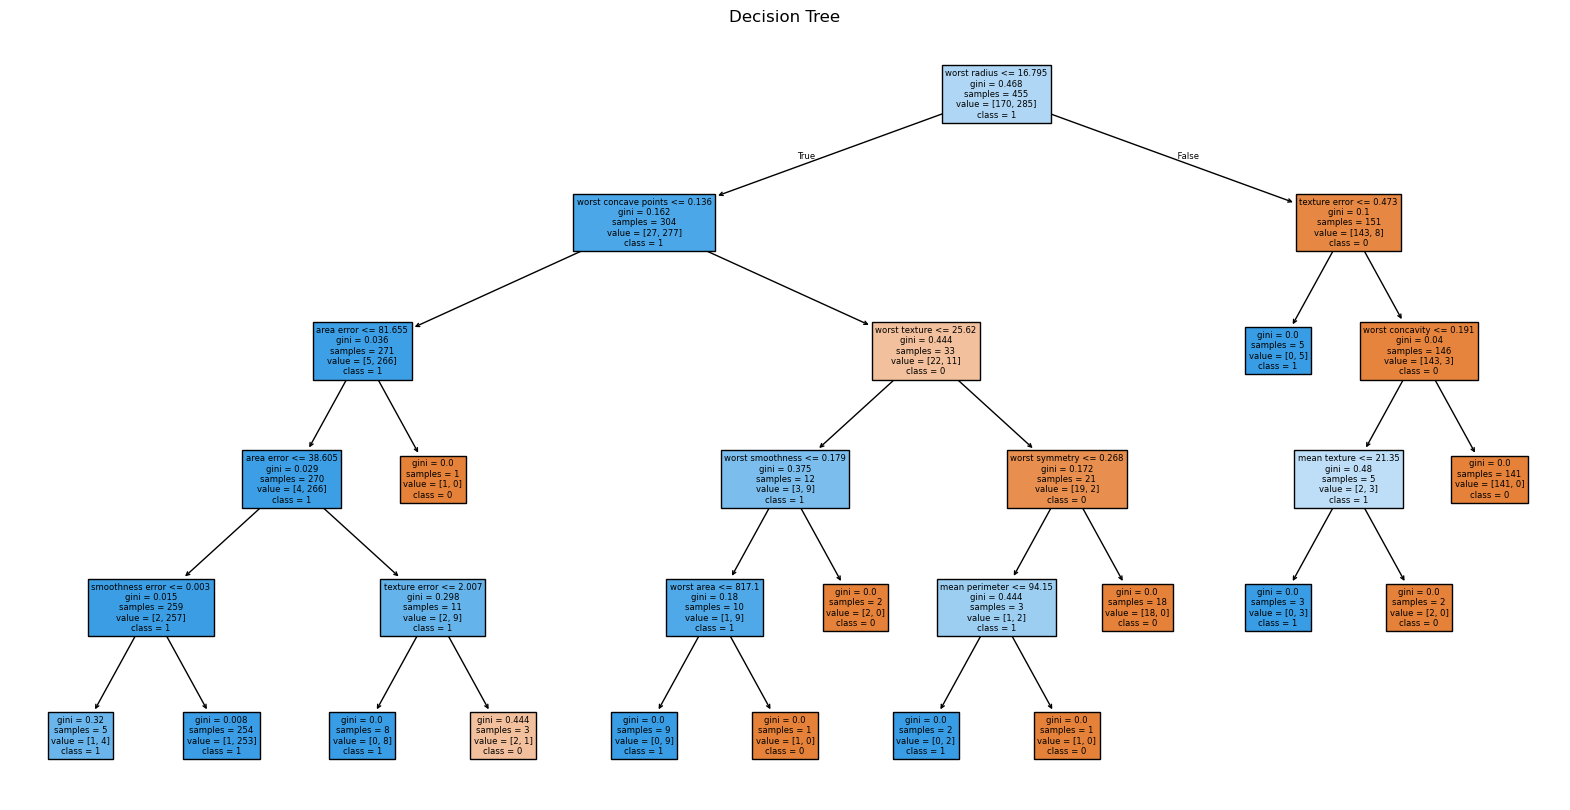

In [53]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=["0", "1"],
    filled=True
)

plt.title("Decision Tree")
plt.show()

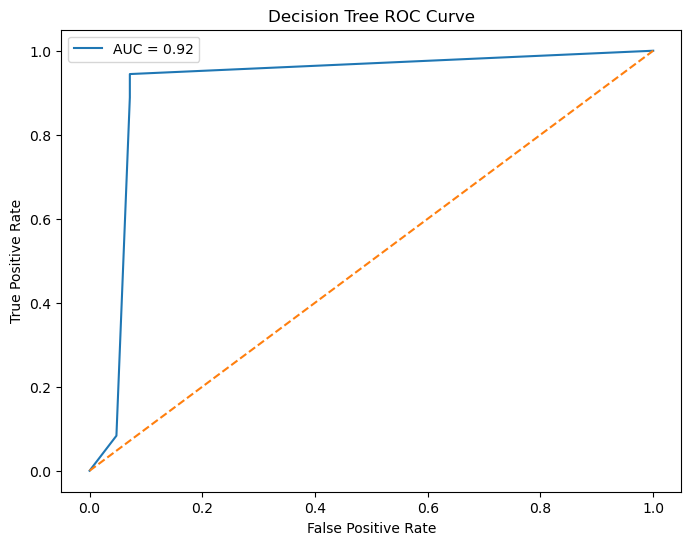

Decision Tree ROC-AUC: 0.9163359788359788


In [54]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Probability prediction
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

# ROC values
fpr_dt, tpr_dt, thresholds_dt = roc_curve(y_test, y_prob_dt)

# AUC
auc_dt = roc_auc_score(y_test, y_prob_dt)

# ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr_dt, tpr_dt, label=f"AUC = {auc_dt:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Decision Tree ROC Curve")
plt.legend()
plt.show()

print("Decision Tree ROC-AUC:", auc_dt)

Random Forest

Random Forest  is an ensemble machine learning algorithm that combines multiple Decision Trees to predict a continuous value. 

improve accuracy and reduce overfitting. It is robust and performs well on complex datasets.

It creates multiple Decision Trees using different samples of the data and features. The predictions from all trees are combined, usually by taking their majority, to produce the final prediction



Suitable:
It works well with many features.

It can handle complex patterns.

It usually gives reliable predictions.

In [55]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42)

rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [56]:
y_pred_rf = rf_model.predict(X_test)

In [57]:
from sklearn.metrics import accuracy_score
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print("Random Forest Accuracy:", accuracy_rf)

Random Forest Accuracy: 0.956140350877193


In [58]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Confusion Matrix:
[[39  3]
 [ 2 70]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



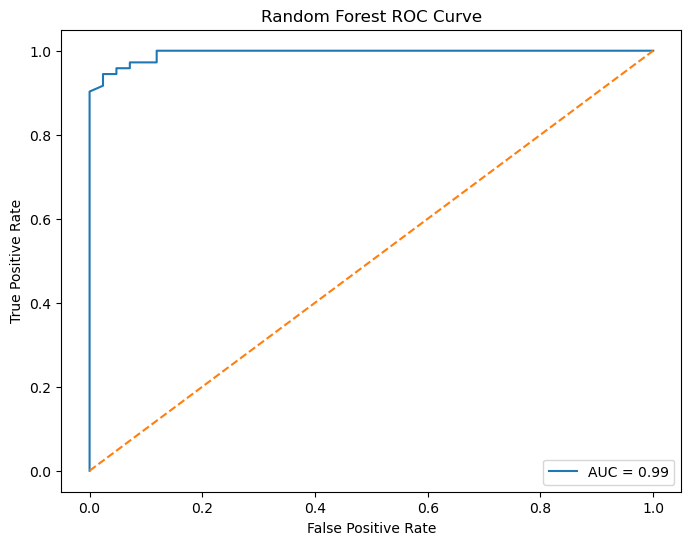

Random Forest ROC-AUC: 0.9942129629629629


In [59]:
from sklearn.metrics import roc_curve, roc_auc_score

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]
fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test, y_prob_rf)
auc_rf = roc_auc_score(y_test, y_prob_rf)

plt.figure(figsize=(8, 6))
plt.plot(fpr_rf, tpr_rf, label=f"AUC = {auc_rf:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curve")
plt.legend()
plt.show()

print("Random Forest ROC-AUC:", auc_rf)

Support Vector Machine (SVM)

It finds the best boundary between classes.
    
It tries to separate the classes clearly.
    
It can handle complex patterns using different kernels.
    
Suitable:

This dataset has many numerical features.
    
It works well for classification problems.
    
It can separate the two classes effectively.



In [60]:
from sklearn.svm import SVC
svm_model = SVC(
    kernel="rbf",
    probability=True,
    random_state=42)

svm_model.fit(X_train_scaled, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,True
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [61]:
y_pred_svm = svm_model.predict(X_test_scaled)

In [62]:
accuracy_svm = accuracy_score(y_test, y_pred_svm)
print("SVM Accuracy:", accuracy_svm)
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))


print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

SVM Accuracy: 0.9824561403508771

Confusion Matrix:
[[41  1]
 [ 1 71]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



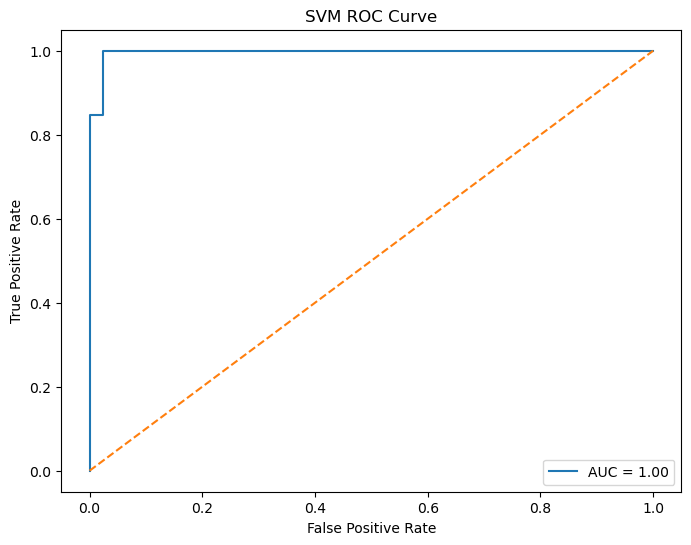

SVM ROC-AUC: 0.9963624338624338


In [63]:
y_prob_svm = svm_model.predict_proba(X_test_scaled)[:, 1]

fpr_svm, tpr_svm, thresholds_svm = roc_curve(
    y_test, y_prob_svm
)

auc_svm = roc_auc_score(y_test, y_prob_svm)

plt.figure(figsize=(8, 6))
plt.plot(fpr_svm, tpr_svm, label=f"AUC = {auc_svm:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("SVM ROC Curve")
plt.legend()
plt.show()

print("SVM ROC-AUC:", auc_svm)

K-Nearest Neighbors (KNN)

Classifies a data point based on its nearest neighbors.

Calculates the distance between data points.

Uses the majority class of the nearest neighbors.

Why suitable:

Works well with numerical features.

Simple and easy to understand.

Feature scaling helps improve its performance.



In [64]:
from sklearn.neighbors import KNeighborsClassifier
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [65]:
y_pred_knn = knn_model.predict(X_test_scaled)

In [66]:
accuracy_knn = accuracy_score(y_test, y_pred_knn)
print("KNN Accuracy:", accuracy_knn)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

KNN Accuracy: 0.9473684210526315

Confusion Matrix:
[[39  3]
 [ 3 69]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93        42
           1       0.96      0.96      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



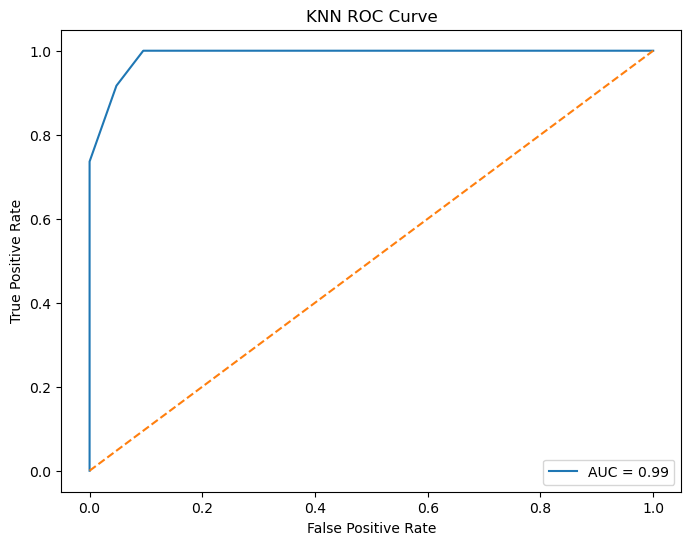

KNN ROC-AUC: 0.9897486772486772


In [67]:
from sklearn.metrics import roc_curve, roc_auc_score

# Probability prediction
y_prob_knn = knn_model.predict_proba(X_test_scaled)[:, 1]

# ROC values
fpr_knn, tpr_knn, thresholds_knn = roc_curve(y_test, y_prob_knn)

# AUC
auc_knn = roc_auc_score(y_test, y_prob_knn)

# ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr_knn, tpr_knn, label=f"AUC = {auc_knn:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("KNN ROC Curve")
plt.legend()
plt.show()

print("KNN ROC-AUC:", auc_knn)

In [68]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

k_values = range(1, 21)
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    
    y_pred = knn.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)
    
    accuracies.append(accuracy)

# Best K
best_k = k_values[accuracies.index(max(accuracies))]
accuracy_knn = max(accuracies)

print("Best K Value:", best_k)
print("Best Accuracy:", accuracy_knn)

Best K Value: 18
Best Accuracy: 0.9824561403508771


In [69]:
knn_model = KNeighborsClassifier(n_neighbors=best_k)

knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)

print("Final KNN Accuracy:",accuracy_knn)
      

Final KNN Accuracy: 0.9824561403508771


In [85]:
results = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "SVM",
        "KNN"
    ],

    "Accuracy": [
        accuracy_logistic,
        accuracy_dt,
        accuracy_rf,
        accuracy_svm,
        accuracy_knn
    ],

      "ROC-AUC": [
        roc_auc_logistic,
        auc_dt,
        auc_rf,
        auc_svm,
        auc_knn
    ]
    
})

results["Accuracy"] = results["Accuracy"].round(4)
results["ROC-AUC"] = results["ROC-AUC"].round(4)
print("MODEL COMPARISON")
print(results)

MODEL COMPARISON
                 Model  Accuracy  ROC-AUC
0  Logistic Regression    0.9825   0.9957
1        Decision Tree    0.9211   0.9163
2        Random Forest    0.9561   0.9942
3                  SVM    0.9825   0.9964
4                  KNN    0.9825   0.9897


In [87]:

# All trained models
models = {
    "Logistic Regression": (logistic_model, X_test_scaled),
    "Decision Tree": (dt_model, X_test),
    "Random Forest": (rf_model, X_test),
    "SVM": (svm_model, X_test_scaled),
    "KNN": (knn_model, X_test_scaled)
}

results = []
predictions = {}

# Evaluate every model
for name, (model, X_eval) in models.items():

    y_pred = model.predict(X_eval)
    predictions[name] = y_pred

    

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    auc = (
        roc_auc_score(y_test, y_score)
        
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": auc
    })

# Final comparison table
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

print("FINAL MODEL COMPARISON")
display(results_df.round(4))

FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,KNN,0.9825,0.9730,1.0000,0.9863,0.9954
1,Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9954
2,SVM,0.9825,0.9861,0.9861,0.9861,0.9954
3,Random Forest,0.9561,0.9589,0.9722,0.9655,0.9954
4,Decision Tree,0.9211,0.9565,0.9167,0.9362,0.9954


In [72]:
for name, (model, X_eval) in models.items():

    print("\n" + "=" * 60)
    print(f"CLASSIFICATION REPORT: {name}")
    print("=" * 60)

    print(
        classification_report(
            y_test,
            predictions[name],
            target_names=["Malignant", "Benign"],
            zero_division=0
        )
    )


CLASSIFICATION REPORT: Logistic Regression
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


CLASSIFICATION REPORT: Decision Tree
              precision    recall  f1-score   support

   Malignant       0.87      0.93      0.90        42
      Benign       0.96      0.92      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114


CLASSIFICATION REPORT: Random Forest
              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro

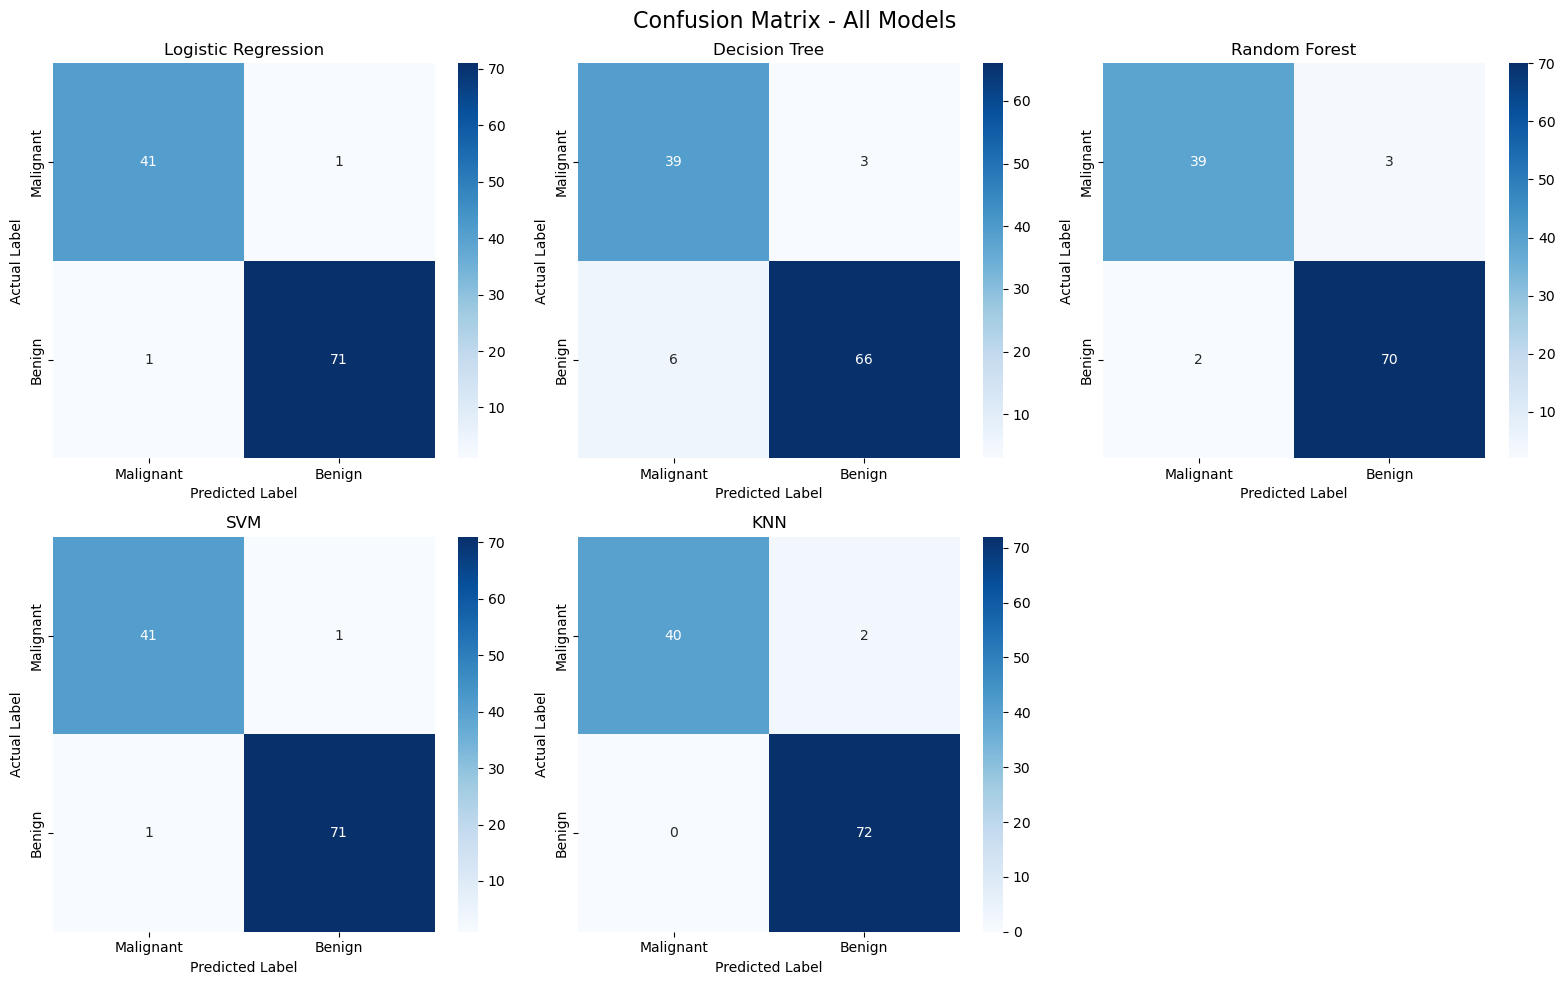

In [73]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(predictions.items()):

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Malignant", "Benign"],
        yticklabels=["Malignant", "Benign"],
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

# Hide unused subplot
for j in range(len(predictions), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Confusion Matrix - All Models", fontsize=16)
plt.tight_layout()
plt.show()

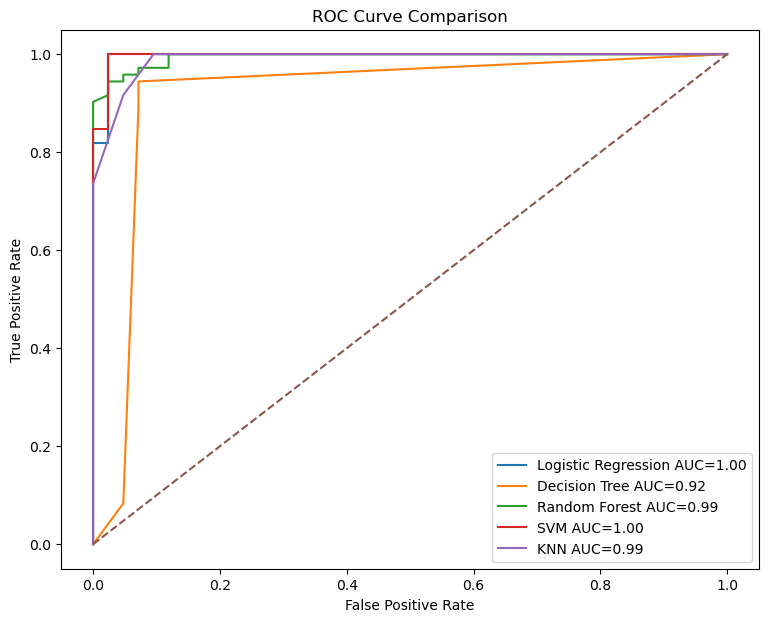

In [82]:
plt.figure(figsize=(9, 7))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression AUC={roc_auc_logistic:.2f}"
)

plt.plot(
    fpr_dt,
    tpr_dt,
    label=f"Decision Tree AUC={auc_dt:.2f}"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest AUC={auc_rf:.2f}"
)

plt.plot(
    fpr_svm,
    tpr_svm,
    label=f"SVM AUC={auc_svm:.2f}"
)

plt.plot(
    fpr_knn,
    tpr_knn,
    label=f"KNN AUC={auc_knn:.2f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.show()

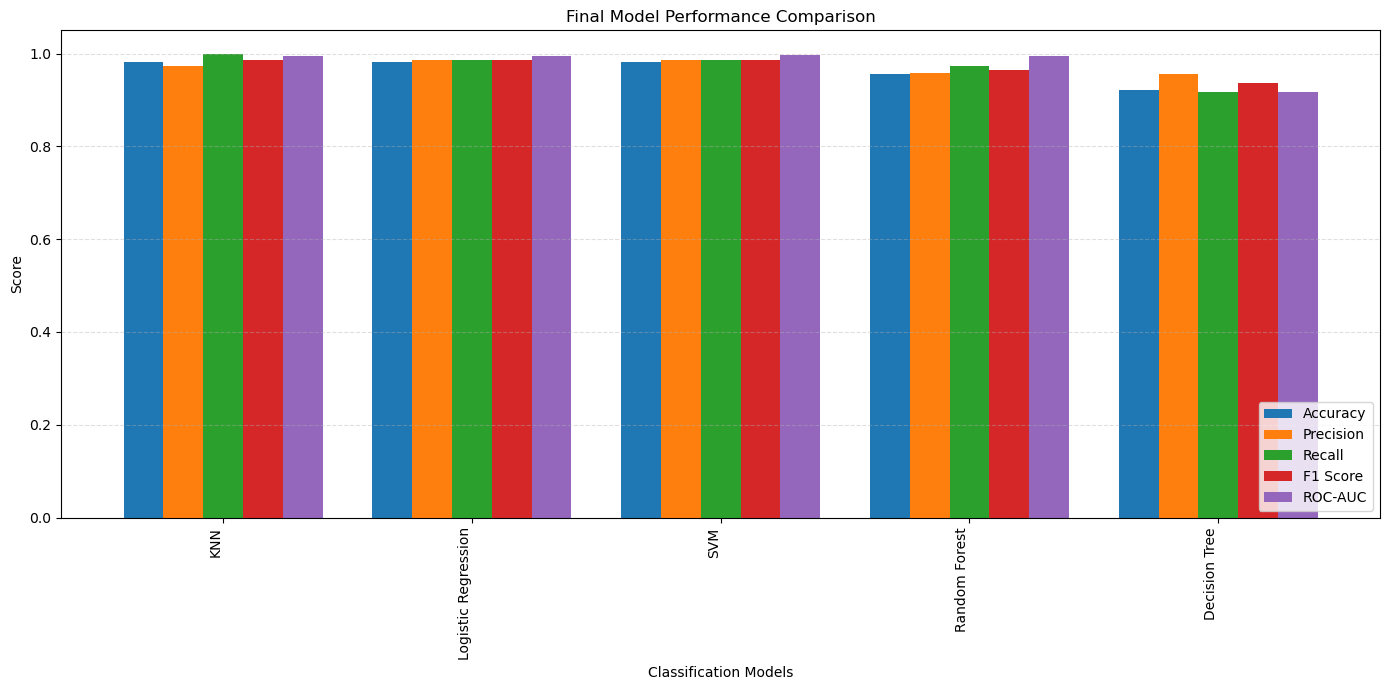

In [83]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(14, 7),
    ylim=(0, 1.05),
    width=0.8
)

plt.title("Final Model Performance Comparison")
plt.xlabel("Classification Models")
plt.ylabel("Score")
plt.xticks(rotation=90, ha="right")
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [77]:
best_model_name = results_df.iloc[0]["Model"]

print("Best Model:", best_model_name)
print("\nBest Model Metrics:")
print(results_df.iloc[0])

Best Model: KNN

Best Model Metrics:
Model             KNN
Accuracy     0.982456
Precision    0.972973
Recall            1.0
F1 Score     0.986301
ROC-AUC       0.99537
Name: 0, dtype: object


In [80]:
worst_accuracy_model = results_df.loc[
    results_df["Accuracy"].idxmin()
]

print("Worst Model based on Accuracy:",
      worst_accuracy_model["Model"])
print("Accuracy:", worst_accuracy_model["Accuracy"])

Worst Model based on Accuracy: Decision Tree
Accuracy: 0.9210526315789473


In [81]:
worst_model = results_df.loc[results_df["F1 Score"].idxmin()]

print("Worst Model:", worst_model["Model"])
print("Accuracy:", worst_model["Accuracy"])
print("Precision:", worst_model["Precision"])
print("Recall:", worst_model["Recall"])
print("F1 Score:", worst_model["F1 Score"])
print("ROC-AUC:", worst_model["ROC-AUC"])

Worst Model: Decision Tree
Accuracy: 0.9210526315789473
Precision: 0.9565217391304348
Recall: 0.9166666666666666
F1 Score: 0.9361702127659575
ROC-AUC: 0.9163359788359788
